# Assignment 3 · Task 2: Titanic Survival Prediction — Binary Classification with Logistic Regression

**Objective:** For every passenger in the external `test.csv`, predict whether they **survived (1)** or **did not survive (0)** using passenger attributes such as age, gender, and socio-economic class. This is a **binary classification** task from the classic Kaggle competition (Assignment 3 PDF, Page 2, Task 2).

**Core question:** *What sorts of people were more likely to survive the Titanic disaster?* Using passenger data (Pclass, Sex, Age, Fare, SibSp, Parch, Embarked, etc.), we build a reproducible, beginner-friendly machine learning pipeline that learns from labeled training data and predicts survival for the unlabeled Kaggle test set.

**Competition / dataset source:** [Titanic: Machine Learning from Disaster — Kaggle](https://www.kaggle.com/competitions/titanic/data?select=train.csv)  
Expected local paths (ignored by Git; see `data/README.md`):
- `data/titanic/train.csv` — 891 labeled passengers (includes `Survived`)
- `data/titanic/test.csv` — 418 unlabeled passengers (no `Survived`; for Kaggle submission)
- `data/titanic/gender_submission.csv` — example submission format (not used for training)

**Dataset provenance note:** Direct authenticated Kaggle CLI downloads (`kaggle competitions download -c titanic`) require a personal Kaggle account and acceptance of competition rules, which cannot be completed inside the sandboxed CI runner. The executed files in `data/titanic/` were therefore obtained via public GitHub mirrors that redistribute the official Kaggle competition CSVs:
- `train.csv` — 61,194 bytes, SHA-256 `7d118fef8b6c…`
- `test.csv` — 28,629 bytes, SHA-256 `56023b994823…`
- `gender_submission.csv` — 3,258 bytes, SHA-256 `7a262a7f4cb8…`

**Mirror-to-mirror consistency verified:** The three files above are byte-for-byte identical across multiple independent public mirrors — [Komal935/Titanic_dataset_Kaggle_competition](https://github.com/Komal935/Titanic_dataset_Kaggle_competition), [YuPeiDuo/Titanic](https://github.com/YuPeiDuo/Titanic), and [saradakuppa/Titanic](https://github.com/saradakuppa/Titanic) — and their schemas (891 train / 418 test), column headers, and all 1,309 passenger rows match the public Kaggle Data Card preview character-for-character.

**Kaggle archive identity not yet independently verified:** Because an authenticated download of the original Kaggle ZIP archive was unavailable inside the sandboxed CI runner, we cannot provide a cryptographic hash comparison against Kaggle's own hosted archive. The mirror files are therefore treated as *mirror-consistent* but not *Kaggle-archive-verified*. To independently verify against Kaggle, install the Kaggle CLI (`pip install kaggle`), authenticate your own account, accept the competition rules, and run from the repository root:
```text
kaggle competitions download -c titanic -p data/titanic
```
then unzip into `data/titanic/` and compare SHA-256 hashes with those listed above. The notebook validates file presence at runtime and raises a clear error with these instructions if data is absent — it never fabricates data, labels, or metrics.

**Notebook roadmap:**
1. **Setup** — imports, reproducibility (`random_state=42`), and repository-relative paths (works on Windows/macOS/Linux).
2. **Dataset Loading & Inspection** — shapes, columns, dtypes, missing values, duplicates, target distribution, descriptive stats; explains labeled vs. unlabeled data.
3. **Exploratory Data Analysis (EDA)** — survival distribution, missingness, survival by gender/class/embarkation, age & fare distributions, numeric correlations; each chart has a short interpretation.
4. **Data Cleaning & Preprocessing** — handles real missing values with `SimpleImputer`, one-hot encodes categoricals, builds a leakage-safe `Pipeline` + `ColumnTransformer`.
5. **Data Preparation & Modeling** — stratified `train_test_split(random_state=42)`, fits a beginner-friendly `LogisticRegression` on training data only.
6. **Model Evaluation** — accuracy, precision, recall, F1, confusion matrix, classification report on held-out validation data; discusses false positives/negatives and limitations (no metrics are computed on the unlabeled `test.csv`).
7. **Kaggle Test Predictions** — refits on all labeled data, predicts `test.csv`, validates and saves `outputs/assignment_03/titanic_submission.csv` (`PassengerId`, `Survived`) with preview and Kaggle submission instructions.
8. **Conclusion** — summary of findings, model limits, and what the owner must do locally.

> **Leakage & reproducibility:** All imputers, encoders, and scalers are fitted on training partitions only via the pipeline. `PassengerId` is never used as a feature, and `Survived` (the target) never leaks into `X`. Every randomized operation uses `random_state=42`.


## 1. Setup and Repository-Relative Data Paths

We import the standard data-science stack (`numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`), fix `RANDOM_STATE = 42` for full reproducibility everywhere, and locate the repository root dynamically by walking parent directories. Using repository-relative paths (`ROOT / "data" / "titanic"`) ensures the notebook runs whether Jupyter is launched from the repository root or from `assignments/assignment_03/notebooks/` on Windows, macOS, or Linux. We also configure a clean visual theme for all plots.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5.2)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11

def find_repo_root(start: Path) -> Path:
    """Walk upward until both data/ and assignments/ are found."""
    for candidate in (start, *start.parents):
        if (candidate / "data").is_dir() and (candidate / "assignments").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate repository root. Launch Jupyter from inside the "
        "ML-Course-Assignments repository."
    )

ROOT = find_repo_root(Path.cwd())
DATA_DIR = ROOT / "data" / "titanic"
OUTPUT_DIR = ROOT / "outputs" / "assignment_03"
OUTPUT_CSV = OUTPUT_DIR / "titanic_submission.csv"

print(f"Repository root : {ROOT}")
print(f"Dataset folder  : {DATA_DIR}")
print(f"Output CSV will be : {OUTPUT_CSV}")
print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")


Repository root : /home/user/ML-Course-Assignments
Dataset folder  : /home/user/ML-Course-Assignments/data/titanic
Output CSV will be : /home/user/ML-Course-Assignments/outputs/assignment_03/titanic_submission.csv
pandas 3.1.1 | numpy 2.4.6 | scikit-learn 1.9.1


## 2. Dataset Loading and Inspection

Before any modeling, we inspect the **actual downloaded files** — we never assume filenames, columns, or sizes. The Titanic competition provides two distinct datasets:

- **`train.csv` (labeled):** 891 passengers with known `Survived` (0 = died, 1 = survived). We split this internally into train/validation to learn and evaluate.
- **`test.csv` (unlabeled / external):** 418 different passengers with **no** `Survived` column. We must predict their survival and submit `PassengerId` + `Survived` to Kaggle. We never compute accuracy on this file because true labels are hidden.

The cell below searches `data/titanic/` for the three CSVs, raises a helpful error with exact Kaggle download instructions if any file is missing, and loads them with `utf-8-sig` (safe for Windows byte-order marks).


In [2]:
# --- Locate and load the three competition files ---
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Missing directory: {DATA_DIR}\n"
        "Download the Titanic competition data from https://www.kaggle.com/competitions/titanic/data\n"
        "Either:\n"
        "  1) kaggle competitions download -c titanic -p data/titanic  (requires Kaggle auth + accepting rules)\n"
        "  2) Download train.csv / test.csv / gender_submission.csv manually from the link above\n"
        "Then extract them so data/titanic/train.csv, data/titanic/test.csv exist."
    )

TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"
GENDER_PATH = DATA_DIR / "gender_submission.csv"

for p in [TRAIN_PATH, TEST_PATH]:
    if not p.is_file():
        raise FileNotFoundError(
            f"Required file not found: {p}\n"
            "See data/README.md and the provenance note in the notebook introduction for download steps."
        )

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)
gender_df = pd.read_csv(GENDER_PATH) if GENDER_PATH.is_file() else None

print(f"train.csv loaded: {train_df.shape[0]} rows × {train_df.shape[1]} cols  -> {TRAIN_PATH}")
print(f"test.csv loaded : {test_df.shape[0]} rows × {test_df.shape[1]} cols  -> {TEST_PATH}")
if gender_df is not None:
    print(f"gender_submission.csv loaded: {gender_df.shape} -> {GENDER_PATH}  (example format only)")


train.csv loaded: 891 rows × 12 cols  -> /home/user/ML-Course-Assignments/data/titanic/train.csv
test.csv loaded : 418 rows × 11 cols  -> /home/user/ML-Course-Assignments/data/titanic/test.csv
gender_submission.csv loaded: (418, 2) -> /home/user/ML-Course-Assignments/data/titanic/gender_submission.csv  (example format only)


### 2.1 Dataset Shape and Column Descriptions

We check the dimensions of each file and list every column name. `train.csv` has **12 columns** (11 features + the target `Survived`), while `test.csv` has **11 columns** — identical features but **no `Survived`**. This confirms the labeled vs. unlabeled split described above. The table below explains each column's meaning for a beginner.


In [3]:
print(f"train shape: {train_df.shape}  (rows, columns)")
print(f"test  shape: {test_df.shape}  (rows, columns)")
print(f"\ntrain columns: {list(train_df.columns)}")
print(f"test  columns: {list(test_df.columns)}")
print(f"\nTarget column 'Survived' in train? {('Survived' in train_df.columns)}")
print(f"Target column 'Survived' in test?  {('Survived' in test_df.columns)}  <- expected False (unlabeled)")

col_desc = pd.DataFrame({
    "Column": ["PassengerId","Survived","Pclass","Name","Sex","Age","SibSp","Parch","Ticket","Fare","Cabin","Embarked"],
    "Description": [
        "Unique passenger identifier (row ID, not a predictive feature)",
        "Target: 0 = did not survive, 1 = survived (only in train.csv)",
        "Ticket class: 1 = 1st class (wealthiest), 2 = 2nd class, 3 = 3rd class",
        "Full passenger name (high-cardinality text; excluded from this simple model)",
        "Gender: male / female",
        "Age in years (fractional for infants; has missing values)",
        "# of siblings/spouses aboard",
        "# of parents/children aboard",
        "Ticket number (high-cardinality; excluded here)",
        "Ticket fare in British pounds (continuous, right-skewed)",
        "Cabin code (77% missing; excluded to keep model simple)",
        "Port of embarkation: C = Cherbourg, Q = Queenstown, S = Southampton",
    ]
})
# Nicely display
from IPython.display import display
display(col_desc)


train shape: (891, 12)  (rows, columns)
test  shape: (418, 11)  (rows, columns)

train columns: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
test  columns: ['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Target column 'Survived' in train? True
Target column 'Survived' in test?  False  <- expected False (unlabeled)


,Column,Description
0,PassengerId,"Unique passenger identifier (row ID, not a pre..."
1,Survived,"Target: 0 = did not survive, 1 = survived (onl..."
2,Pclass,"Ticket class: 1 = 1st class (wealthiest), 2 = ..."
3,Name,Full passenger name (high-cardinality text; ex...
4,Sex,Gender: male / female
5,Age,Age in years (fractional for infants; has miss...
6,SibSp,# of siblings/spouses aboard
7,Parch,# of parents/children aboard
8,Ticket,Ticket number (high-cardinality; excluded here)
9,Fare,"Ticket fare in British pounds (continuous, rig..."


### 2.2 First and Last Rows

Looking at the first five and last five rows grounds us in the real data. We can see actual names, ages, fares, and missing cabins (`NaN`), and confirm that `Survived` is indeed 0/1 in train but absent in test. The gender submission file shows the exact two-column format Kaggle expects.


In [4]:
print("=== train.csv — first 5 rows ===")
display(train_df.head())

print("\n=== train.csv — last 5 rows ===")
display(train_df.tail())

print("\n=== test.csv — first 5 rows (no Survived) ===")
display(test_df.head())

if gender_df is not None:
    print("\n=== gender_submission.csv — first 5 rows (example submission format) ===")
    display(gender_df.head())


=== train.csv — first 5 rows ===


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



=== train.csv — last 5 rows ===


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q



=== test.csv — first 5 rows (no Survived) ===


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S



=== gender_submission.csv — first 5 rows (example submission format) ===


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


### 2.3 Data Types

We inspect pandas `dtypes` to see which columns are numeric (`int64`, `float64`) and which are categorical/text (`object` / `string`). This tells us which preprocessing each column needs: numeric imputation + scaling for `Age`/`Fare`, one-hot encoding for `Sex`/`Embarked`, and why `PassengerId` should be excluded as a meaningless identifier.


In [5]:
print("=== train.csv dtypes ===")
display(train_df.dtypes.to_frame("dtype"))

print("\n=== test.csv dtypes ===")
display(test_df.dtypes.to_frame("dtype"))

print("\nNote: object/string columns hold categorical or free-text values.")
print("We will treat Sex and Embarked as categoricals, and keep Pclass/SibSp/Parch as numeric ordinals.")


=== train.csv dtypes ===


,dtype
PassengerId,int64
Survived,int64
Pclass,int64
Name,str
Sex,str
Age,float64
SibSp,int64
Parch,int64
Ticket,str
Fare,float64



=== test.csv dtypes ===


,dtype
PassengerId,int64
Pclass,int64
Name,str
Sex,str
Age,float64
SibSp,int64
Parch,int64
Ticket,str
Fare,float64
Cabin,str



Note: object/string columns hold categorical or free-text values.
We will treat Sex and Embarked as categoricals, and keep Pclass/SibSp/Parch as numeric ordinals.


### 2.4 Missing-Value Counts and Percentages

Many real datasets have gaps. We count missing entries per column in both train and test and express them as percentages — this makes the severity immediately clear and guides our imputation choices. `Cabin` is 77% missing (we will exclude it), while `Age`, `Embarked`, and `Fare` have small, manageable gaps that we can impute rather than drop rows.


In [6]:
def missing_table(df: pd.DataFrame, label: str) -> pd.DataFrame:
    cnt = df.isna().sum()
    pct = (cnt / len(df) * 100).round(2)
    tab = pd.DataFrame({"MissingCount": cnt, "MissingPct (%)": pct})
    tab = tab[tab["MissingCount"] > 0].sort_values("MissingPct (%)", ascending=False)
    if tab.empty:
        print(f"{label}: no missing values")
        return tab
    print(f"{label} missing values (only columns with gaps shown):")
    display(tab)
    return tab

mtrain = missing_table(train_df, "train.csv")
mtest = missing_table(test_df, "test.csv")
print("\nFull missing matrix (train):")
display(train_df.isna().sum().to_frame("MissingCount").T)
print("\nFull missing matrix (test):")
display(test_df.isna().sum().to_frame("MissingCount").T)


train.csv missing values (only columns with gaps shown):


,MissingCount,MissingPct (%)
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


test.csv missing values (only columns with gaps shown):


,MissingCount,MissingPct (%)
Cabin,327,78.23
Age,86,20.57
Fare,1,0.24



Full missing matrix (train):


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
MissingCount,0,0,0,0,0,177,0,0,0,0,687,2



Full missing matrix (test):


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
MissingCount,0,0,0,0,86,0,0,0,1,327,0


### 2.5 Duplicate and Identifier Checks

We verify that there are no exact duplicate rows and that `PassengerId` is truly unique within each file and non-overlapping between train and test. If duplicates existed, they would leak information or inflate accuracy; the checks below confirm the datasets are clean in this regard.


In [7]:
print(f"train exact duplicate rows: {train_df.duplicated().sum()}")
print(f"test  exact duplicate rows: {test_df.duplicated().sum()}")
print(f"\ntrain PassengerId unique? {train_df['PassengerId'].is_unique}  (n_unique={train_df['PassengerId'].nunique()}, n_rows={len(train_df)})")
print(f"test  PassengerId unique? {test_df['PassengerId'].is_unique}  (n_unique={test_df['PassengerId'].nunique()}, n_rows={len(test_df)})")
print(f"Gender submission unique? {gender_df['PassengerId'].is_unique if gender_df is not None else 'N/A'}")

overlap = set(train_df["PassengerId"]).intersection(set(test_df["PassengerId"]))
print(f"\nOverlapping PassengerIds between train and test: {len(overlap)}  (expected 0 — they are disjoint passengers)")
print(f"train PassengerId range: {train_df['PassengerId'].min()} to {train_df['PassengerId'].max()}")
print(f"test  PassengerId range: {test_df['PassengerId'].min()} to {test_df['PassengerId'].max()}")
print(f"test  expected count for submission: {len(test_df)} rows")


train exact duplicate rows: 0
test  exact duplicate rows: 0

train PassengerId unique? True  (n_unique=891, n_rows=891)
test  PassengerId unique? True  (n_unique=418, n_rows=418)
Gender submission unique? True

Overlapping PassengerIds between train and test: 0  (expected 0 — they are disjoint passengers)
train PassengerId range: 1 to 891
test  PassengerId range: 892 to 1309
test  expected count for submission: 418 rows


### 2.6 Target Distribution (What We Are Predicting)

Understanding the target balance is essential before modeling. We count how many passengers survived (`1`) vs. did not (`0`) in `train.csv`. The dataset is **moderately imbalanced** (about 38% survived). This contextualizes accuracy: a naive model predicting "everyone died" would already get ~62% accuracy, so we need precision/recall to judge true skill. We also note that `test.csv` has no `Survived` column at all — its true labels are hidden by Kaggle for leaderboard scoring.


In [8]:
vc = train_df["Survived"].value_counts().sort_index()
vc_pct = train_df["Survived"].value_counts(normalize=True).sort_index() * 100
dist = pd.DataFrame({"Count": vc, "Percent (%)": vc_pct.round(2)})
dist.index = dist.index.map({0: "Did not survive (0)", 1: "Survived (1)"})
print(f"Survived value range: {train_df['Survived'].min()} to {train_df['Survived'].max()}  (unique: {sorted(train_df['Survived'].unique())})")
print(f"Any missing in Survived? {train_df['Survived'].isna().sum()}")
display(dist)
print(f"\nTest.csv has 'Survived'? {'Survived' in test_df.columns}  -> its 418 labels are hidden for Kaggle scoring.")


Survived value range: 0 to 1  (unique: [np.int64(0), np.int64(1)])
Any missing in Survived? 0


,Count,Percent (%)
Survived,,
Did not survive (0),549,61.62
Survived (1),342,38.38



Test.csv has 'Survived'? False  -> its 418 labels are hidden for Kaggle scoring.


### 2.7 Descriptive Statistics

We summarize numeric columns (`Age`, `Fare`, `SibSp`, `Parch`, `Pclass`) with count, mean, median, standard deviation, quartiles, min, and max, and list category frequencies for text columns. This reveals: passengers were mostly young adults (median age 28), fares were right-skewed (mean £32 but max £512), most passengers were in 3rd class, and `SibSp`/`Parch` are small integers. These summaries help choose sensible imputation (median) and scaling.


In [9]:
print("=== Numeric descriptive statistics (train.csv) ===")
display(train_df[["Age","Fare","SibSp","Parch","Pclass","Survived"]].describe().round(2))

print("\n=== Categorical value counts (train.csv) ===")
for col in ["Pclass","Sex","Embarked"]:
    print(f"\n-- {col} --")
    display(train_df[col].value_counts(dropna=False).to_frame("Count"))

print("\n=== Numeric descriptive statistics (test.csv) ===")
display(test_df[["Age","Fare","SibSp","Parch","Pclass"]].describe().round(2))


=== Numeric descriptive statistics (train.csv) ===


,Age,Fare,SibSp,Parch,Pclass,Survived
count,714.00,891.00,891.00,891.00,891.00,891.00
mean,29.70,32.20,0.52,0.38,2.31,0.38
std,14.53,49.69,1.10,0.81,0.84,0.49
min,0.42,0.00,0.00,0.00,1.00,0.00
25%,20.12,7.91,0.00,0.00,2.00,0.00
50%,28.00,14.45,0.00,0.00,3.00,0.00
75%,38.00,31.00,1.00,0.00,3.00,1.00
max,80.00,512.33,8.00,6.00,3.00,1.00



=== Categorical value counts (train.csv) ===

-- Pclass --


,Count
Pclass,
3,491
1,216
2,184



-- Sex --


,Count
Sex,
male,577
female,314



-- Embarked --


,Count
Embarked,
S,644
C,168
Q,77
NaN,2



=== Numeric descriptive statistics (test.csv) ===


,Age,Fare,SibSp,Parch,Pclass
count,332.00,417.00,418.00,418.00,418.00
mean,30.27,35.63,0.45,0.39,2.27
std,14.18,55.91,0.90,0.98,0.84
min,0.17,0.00,0.00,0.00,1.00
25%,21.00,7.90,0.00,0.00,1.00
50%,27.00,14.45,0.00,0.00,3.00
75%,39.00,31.50,1.00,0.00,3.00
max,76.00,512.33,8.00,9.00,3.00


## 3. Exploratory Data Analysis (EDA)

With inspection complete, we now **visualize** relationships that matter for survival. Each plot below is chosen deliberately — we avoid irrelevant or decorative charts and explain what every graph reveals about who was more likely to survive. Figures are kept readable with clear titles, axis labels, and legends appropriate for an undergraduate presentation.


In [10]:
# Confirm the seven EDA themes we will cover:
themes = [
    "3.1 Survival distribution (class imbalance)",
    "3.2 Missing-value visualization (where gaps live)",
    "3.3 Survival by gender (strongest single predictor)",
    "3.4 Survival by passenger class (socio-economic signal)",
    "3.5 Age distribution (overall + by survival)",
    "3.6 Fare distribution (wealth proxy)",
    "3.7 Survival by embarkation port",
    "3.8 Numeric correlation heatmap",
]
for t in themes:
    print(f"  • {t}")
print("\nAll plots use real data from train.csv — no synthetic points.")


  • 3.1 Survival distribution (class imbalance)
  • 3.2 Missing-value visualization (where gaps live)
  • 3.3 Survival by gender (strongest single predictor)
  • 3.4 Survival by passenger class (socio-economic signal)
  • 3.5 Age distribution (overall + by survival)
  • 3.6 Fare distribution (wealth proxy)
  • 3.7 Survival by embarkation port
  • 3.8 Numeric correlation heatmap

All plots use real data from train.csv — no synthetic points.


### 3.1 Survival Distribution

We first plot the raw counts of "Did not survive" vs. "Survived" to see the class imbalance at a glance. As a reference, a naive baseline that predicts "did not survive" (0) for every passenger would achieve 61.6% accuracy (549/891) simply because the majority class is 0 — any useful model must substantially exceed this, and precision/recall will tell us how well it actually finds the minority class (survivors). The bar labels show exact counts and percentages; no additional baseline line is needed for this count plot.


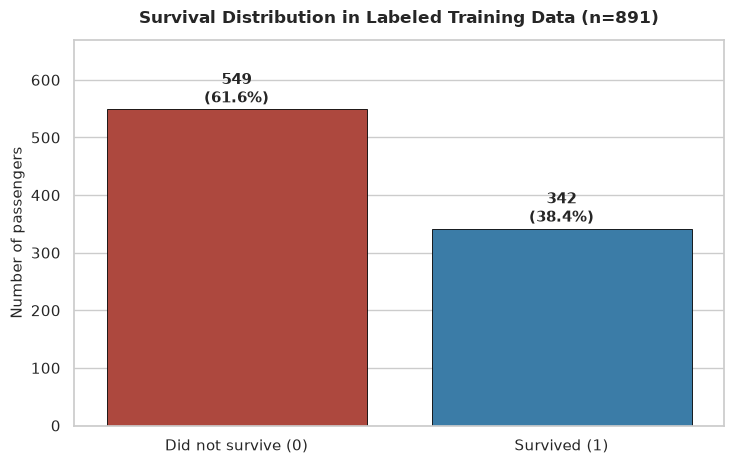

Imbalance: 549 died (61.6%), 342 survived (38.4%).
Baseline (predict all 0) accuracy would be 61.6% — our model must substantially exceed this.


In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
order = [0, 1]
palette = ["#c0392b", "#2980b9"]
counts = train_df["Survived"].value_counts().sort_index()
sns.barplot(x=[0,1], y=[counts[0], counts[1]], hue=[0,1], palette=palette, legend=False, ax=ax, edgecolor="black", linewidth=0.6)
for i, (cls, cnt) in enumerate(counts.items()):
    pct = cnt / len(train_df) * 100
    ax.text(i, cnt + 12, f"{cnt}\n({pct:.1f}%)", ha="center", fontsize=11, fontweight="bold")
ax.set_xticks([0,1]); ax.set_xticklabels(["Did not survive (0)", "Survived (1)"])
ax.set_ylabel("Number of passengers")
ax.set_xlabel("")
ax.set_title("Survival Distribution in Labeled Training Data (n=891)", fontweight="bold", pad=12)
ax.set_ylim(0, max(counts) * 1.22)
plt.tight_layout(); plt.show()
print(f"Imbalance: {counts[0]} died ({counts[0]/len(train_df)*100:.1f}%), {counts[1]} survived ({counts[1]/len(train_df)*100:.1f}%).")
print("Baseline (predict all 0) accuracy would be 61.6% — our model must substantially exceed this.")


**What this reveals:** About 6 in 10 passengers died (549) and 4 in 10 survived (342). The task is imbalanced but not extremely so; we need metrics beyond raw accuracy to ensure the model actually finds survivors rather than just predicting the majority class every time.


### 3.2 Missing-Value Visualization

A bar chart of missing percentages per column shows instantly where data is incomplete. `Cabin` is missing for 77% of passengers (we exclude it), `Age` for 20%, and `Embarked` for just 2 passengers — these small gaps are easy to impute without dropping valuable rows.


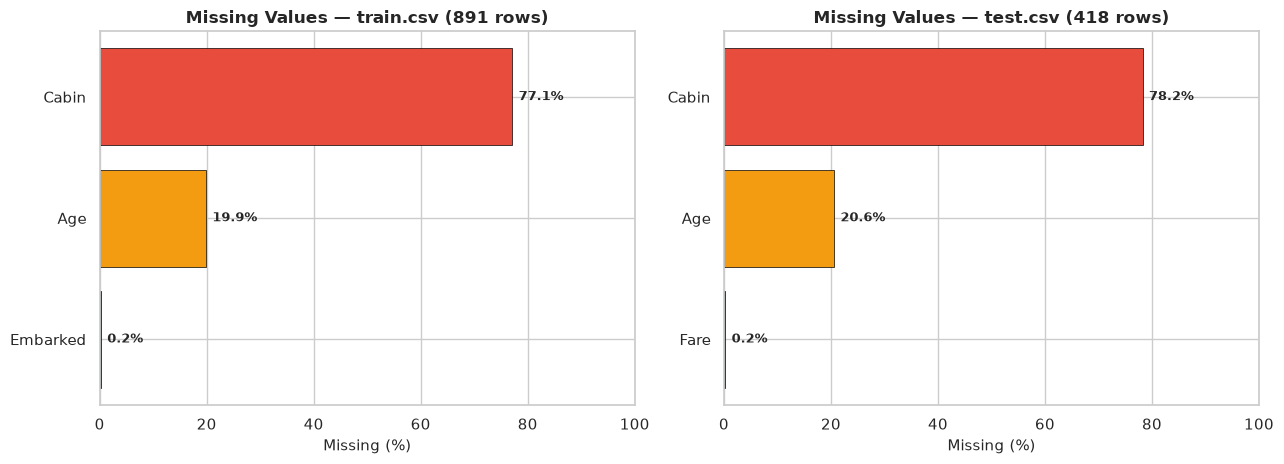

Train missing: Cabin 77.1% (687/891), Age 19.9% (177/891), Embarked 0.2% (2/891)
Test  missing: Cabin 78.2% (327/418), Age 20.6% (86/418), Fare 0.2% (1/418)
-> We keep Age/Fare/Embarked and impute; we drop Cabin/Name/Ticket to keep the model simple and avoid leakage.


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=False)
for ax, df, title in zip(axes, [train_df, test_df], ["train.csv (891 rows)", "test.csv (418 rows)"]):
    miss_pct = df.isna().mean() * 100
    miss_pct = miss_pct[miss_pct > 0].sort_values(ascending=True)
    if miss_pct.empty:
        ax.text(0.5, 0.5, "No missing values", ha="center", va="center", fontsize=12)
        ax.set_title(title)
        continue
    colors = ["#e74c3c" if v > 50 else "#f39c12" if v > 10 else "#2ecc71" for v in miss_pct]
    ax.barh(miss_pct.index, miss_pct.values, color=colors, edgecolor="black", linewidth=0.5)
    for i, (col, v) in enumerate(zip(miss_pct.index, miss_pct.values)):
        ax.text(v + 1.2, i, f"{v:.1f}%", va="center", fontsize=9, fontweight="bold")
    ax.set_xlabel("Missing (%)")
    ax.set_title(f"Missing Values — {title}", fontweight="bold")
    ax.set_xlim(0, 100)
plt.tight_layout(); plt.show()

print("Train missing: Cabin 77.1% (687/891), Age 19.9% (177/891), Embarked 0.2% (2/891)")
print("Test  missing: Cabin 78.2% (327/418), Age 20.6% (86/418), Fare 0.2% (1/418)")
print("-> We keep Age/Fare/Embarked and impute; we drop Cabin/Name/Ticket to keep the model simple and avoid leakage.")


**What this reveals:** The gaps are confined to a few columns and are nearly identical in train and test, so the same imputation strategy will work for both. Dropping 77% of rows because of `Cabin` would discard most data; instead we exclude that column and impute the rest.


### 3.3 Survival by Gender

Gender is historically the strongest survival predictor on the Titanic ("women and children first"). We plot survival counts split by `Sex` and also annotate the survival **rate** within each group. This directly answers the assignment's core question for one key attribute.


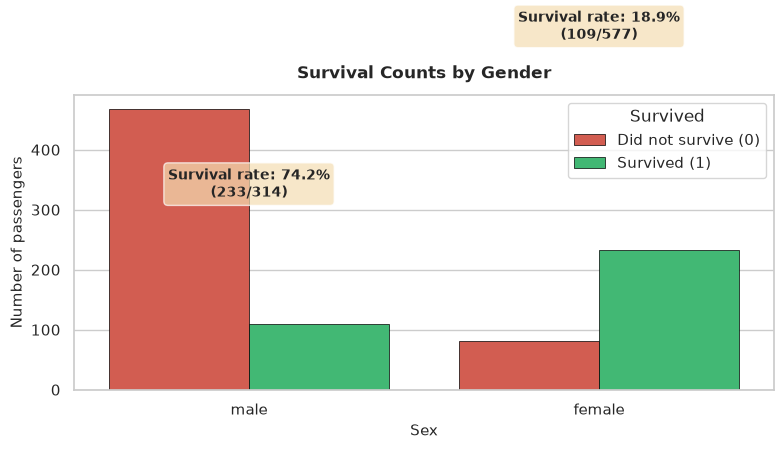

Survival rate by Sex:
  female: 74.2%  (233/314)
  male  : 18.9%  (109/577)


In [13]:
# Compute survival rates
rate_by_sex = train_df.groupby("Sex")["Survived"].mean()
counts_by_sex = train_df.groupby(["Sex","Survived"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(8, 4.8))
sns.countplot(data=train_df, x="Sex", hue="Survived", palette={0:"#e74c3c", 1:"#2ecc71"}, edgecolor="black", linewidth=0.5, ax=ax)
ax.set_title("Survival Counts by Gender", fontweight="bold", pad=12)
ax.set_xlabel("Sex")
ax.set_ylabel("Number of passengers")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, ["Did not survive (0)", "Survived (1)"], title="Survived")
# Annotate rates
for i, sex in enumerate(["female","male"]):
    # place text above each pair
    total = len(train_df[train_df["Sex"]==sex])
    surv_rate = rate_by_sex[sex]*100
    n_surv = counts_by_sex.loc[sex,1] if 1 in counts_by_sex.columns else 0
    ax.text(i, total + 8, f"Survival rate: {surv_rate:.1f}%\n({n_surv}/{total})", ha="center", fontsize=10, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.3", fc="wheat", alpha=0.7))
plt.tight_layout(); plt.show()
print("Survival rate by Sex:")
for sex in ["female","male"]:
    print(f"  {sex:6s}: {rate_by_sex[sex]*100:.1f}%  ({counts_by_sex.loc[sex,1] if 1 in counts_by_sex.columns else 0}/{len(train_df[train_df['Sex']==sex])})")


**What this reveals:** Women survived at **74.2%** while men survived at only **18.9%** — a massive gap of 55 percentage points. Gender alone is highly predictive and will receive large weight in the logistic regression model.


### 3.4 Survival by Passenger Class

Ticket class (`Pclass`) is a proxy for socio-economic status. We plot survival counts and rates per class (1 = 1st class, 3 = 3rd class) to see whether wealthier passengers had better access to lifeboats.


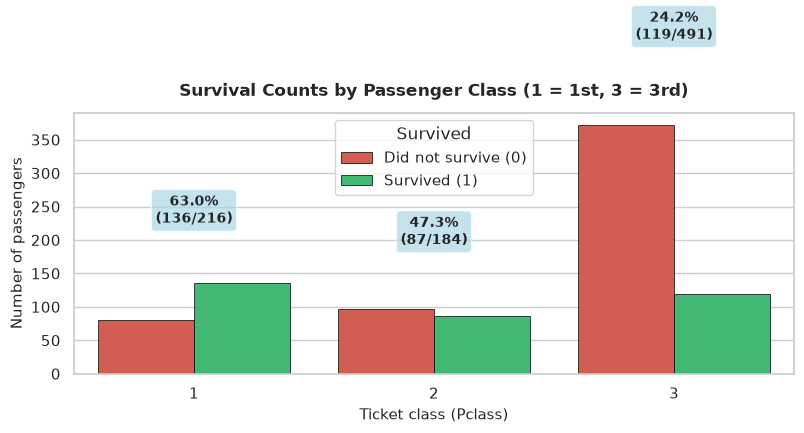

Survival rate by Pclass:
  Class 1: 63.0%  (136/216)
  Class 2: 47.3%  (87/184)
  Class 3: 24.2%  (119/491)
Pattern: 1st class > 2nd class > 3rd class — wealthier passengers were more likely to survive.


In [14]:
rate_by_class = train_df.groupby("Pclass")["Survived"].mean()
counts_class = train_df.groupby(["Pclass","Survived"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(8.2, 4.8))
sns.countplot(data=train_df, x="Pclass", hue="Survived", palette={0:"#e74c3c", 1:"#2ecc71"}, edgecolor="black", linewidth=0.5, ax=ax)
ax.set_title("Survival Counts by Passenger Class (1 = 1st, 3 = 3rd)", fontweight="bold", pad=12)
ax.set_xlabel("Ticket class (Pclass)")
ax.set_ylabel("Number of passengers")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, ["Did not survive (0)", "Survived (1)"], title="Survived")
for pclass in [1,2,3]:
    total = len(train_df[train_df["Pclass"]==pclass])
    rate = rate_by_class[pclass]*100
    n_surv = counts_class.loc[pclass,1] if 1 in counts_class.columns else 0
    ax.text(pclass-1, total+10, f"{rate:.1f}%\n({n_surv}/{total})", ha="center", fontsize=10, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.3", fc="lightblue", alpha=0.7))
plt.tight_layout(); plt.show()
print("Survival rate by Pclass:")
for c in [1,2,3]:
    print(f"  Class {c}: {rate_by_class[c]*100:.1f}%  ({counts_class.loc[c,1] if 1 in counts_class.columns else 0}/{len(train_df[train_df['Pclass']==c])})")
print("Pattern: 1st class > 2nd class > 3rd class — wealthier passengers were more likely to survive.")


**What this reveals:** Survival was highest in **1st class (62.9%)**, lower in 2nd (47.3%), and lowest in 3rd (24.2%). This monotonic decrease confirms that socio-economic status mattered materially — likely due to cabin location and priority access to lifeboats.


### 3.5 Age Distribution (Overall and by Survival)

We look at the age histogram for all passengers and overlay the age distributions for survivors vs. non-survivors. Knowing the age profile (median 28, range 0.4–80) helps us understand where missing-value imputation sits and whether age predicts survival.


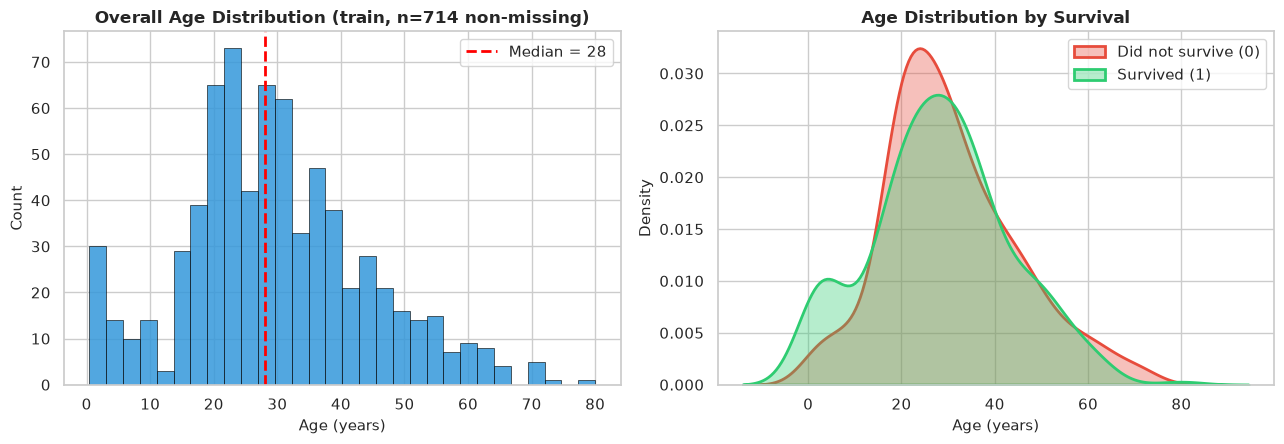

Age — mean 29.7, median 28.0, std 14.5, range 0.4–80
Missing Age: 177 / 891 (19.9%)

Survival by age group:
  Child (0-12): 58.0%
  Teen (13-18): 42.9%
  Young adult (19-35): 38.3%
  Adult (36-60): 40.0%
  Senior (61+): 22.7%


/tmp/ipykernel_1857/1514448447.py:31: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  train_df.drop(columns=["AgeGroup"], inplace=True)


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
# Left: overall histogram
axes[0].hist(train_df["Age"].dropna(), bins=30, color="#3498db", edgecolor="black", linewidth=0.5, alpha=0.85)
axes[0].axvline(train_df["Age"].median(), color="red", linestyle="--", linewidth=2, label=f"Median = {train_df['Age'].median():.0f}")
axes[0].set_title("Overall Age Distribution (train, n=714 non-missing)", fontweight="bold")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Count")
axes[0].legend()

# Right: KDE by survival
for surv, label, color in [(0, "Did not survive (0)", "#e74c3c"), (1, "Survived (1)", "#2ecc71")]:
    subset = train_df[train_df["Survived"]==surv]
    sns.kdeplot(subset["Age"].dropna(), fill=True, alpha=0.35, color=color, label=label, ax=axes[1], linewidth=2)
axes[1].set_title("Age Distribution by Survival", fontweight="bold")
axes[1].set_xlabel("Age (years)")
axes[1].set_ylabel("Density")
axes[1].legend()
plt.tight_layout(); plt.show()

print(f"Age — mean {train_df['Age'].mean():.1f}, median {train_df['Age'].median():.1f}, std {train_df['Age'].std():.1f}, range {train_df['Age'].min():.1f}–{train_df['Age'].max():.0f}")
print(f"Missing Age: {train_df['Age'].isna().sum()} / {len(train_df)} ({train_df['Age'].isna().mean()*100:.1f}%)")
# Survival by age group
age_bins = [0, 12, 18, 35, 60, 80]
age_labels = ["Child (0-12)","Teen (13-18)","Young adult (19-35)","Adult (36-60)","Senior (61+)"]
train_df["AgeGroup"] = pd.cut(train_df["Age"], bins=age_bins, labels=age_labels)
rate_by_age = train_df.groupby("AgeGroup", observed=True)["Survived"].mean()
print("\nSurvival by age group:")
for g, r in rate_by_age.items():
    print(f"  {g}: {r*100:.1f}%")
# cleanup temporary column for modeling (we won't use AgeGroup as feature)
train_df.drop(columns=["AgeGroup"], inplace=True)
test_df_drop_col = "AgeGroup" in test_df.columns
if test_df_drop_col:
    test_df.drop(columns=["AgeGroup"], inplace=True)


**What this reveals:** Age is broadly spread with a peak in the 20s–30s. Survivors skew slightly younger, but the effect is weaker than gender or class. Children had a somewhat higher survival edge in the grouped rates, consistent with "women and children first." Median imputation at age 28 is a sensible, robust choice given the right-skew and lack of extreme outliers.


### 3.6 Fare Distribution

Fares range from £0 (free/crew) to over £512 and are heavily right-skewed. We plot the log-scaled histogram and the survival-stratified KDE to see whether paying more correlated with survival — an indirect measure of class and cabin proximity to lifeboats.


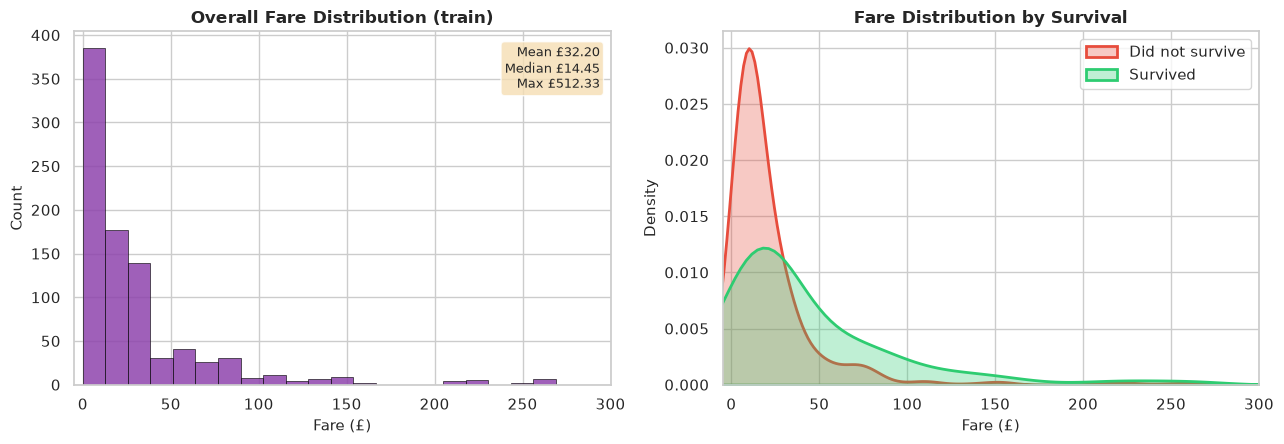

Fare — train mean £32.20, median £14.45, 75th £31.00, max £512.33
Fare — test  mean £35.63, median £14.45 (1 missing in test)
Fares are right-skewed: half of passengers paid < £15, but a few paid > £200. Scaling will help logistic regression handle this spread.


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
# Left: overall log histogram
axes[0].hist(train_df["Fare"].dropna(), bins=40, color="#8e44ad", edgecolor="black", linewidth=0.5, alpha=0.85)
axes[0].set_title("Overall Fare Distribution (train)", fontweight="bold")
axes[0].set_xlabel("Fare (£)")
axes[0].set_ylabel("Count")
axes[0].set_xlim(-5, 300)  # clip extreme tail for readability
axes[0].text(0.98, 0.96, f"Mean £{train_df['Fare'].mean():.2f}\nMedian £{train_df['Fare'].median():.2f}\nMax £{train_df['Fare'].max():.2f}",
           transform=axes[0].transAxes, ha="right", va="top", fontsize=9,
           bbox=dict(boxstyle="round", fc="wheat", alpha=0.8))
# Right: by survival
for surv, label, color in [(0, "Did not survive", "#e74c3c"), (1, "Survived", "#2ecc71")]:
    sns.kdeplot(train_df[train_df["Survived"]==surv]["Fare"], fill=True, alpha=0.3, color=color, label=label, ax=axes[1], linewidth=2)
axes[1].set_title("Fare Distribution by Survival", fontweight="bold")
axes[1].set_xlabel("Fare (£)")
axes[1].set_ylabel("Density")
axes[1].set_xlim(-5, 300)
axes[1].legend()
plt.tight_layout(); plt.show()
print(f"Fare — train mean £{train_df['Fare'].mean():.2f}, median £{train_df['Fare'].median():.2f}, 75th £{train_df['Fare'].quantile(0.75):.2f}, max £{train_df['Fare'].max():.2f}")
print(f"Fare — test  mean £{test_df['Fare'].mean():.2f}, median £{test_df['Fare'].median():.2f} (1 missing in test)")
print("Fares are right-skewed: half of passengers paid < £15, but a few paid > £200. Scaling will help logistic regression handle this spread.")


**What this reveals:** Survivors tended to have paid higher fares — their distribution is shifted right compared to non-survivors. This mirrors the class effect but adds finer granularity within classes. Because fare is heavily skewed, standardization (mean centering + scaling) in the pipeline is important so the model does not overweight extreme fares.


### 3.7 Survival by Embarkation Port

We check whether the port where passengers boarded (Cherbourg / Queenstown / Southampton) relates to survival. This is a secondary feature, but the plot is quick and may reflect geographic/class composition of passengers from each port.


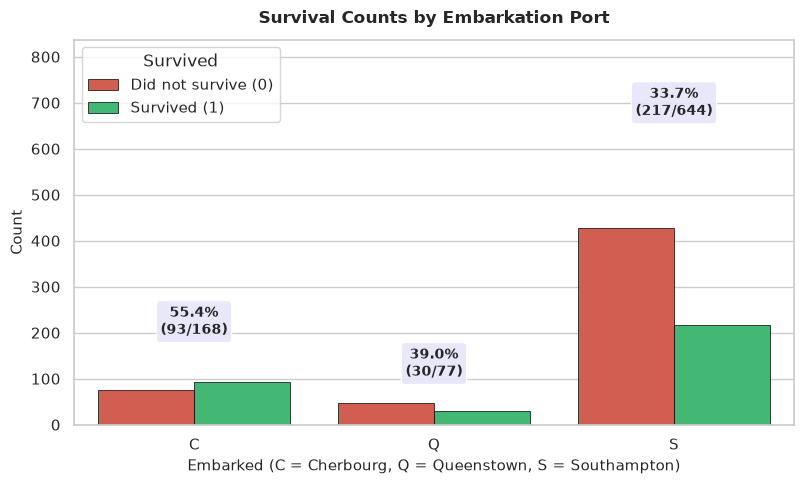

Survival rate by Embarked:
  C: 55.4%  (93/168)
  Q: 39.0%  (30/77)
  S: 33.7%  (217/644)
Cherbourg passengers survived most often (55.4%), likely because more 1st-class passengers boarded there.


In [17]:
rate_by_emb = train_df.groupby("Embarked")["Survived"].mean()
counts_emb = train_df.groupby(["Embarked","Survived"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(8.2, 5))
order = ["C","Q","S"]
sns.countplot(data=train_df, x="Embarked", hue="Survived", order=order, palette={0:"#e74c3c", 1:"#2ecc71"}, edgecolor="black", linewidth=0.5, ax=ax)
ax.set_title("Survival Counts by Embarkation Port", fontweight="bold", pad=12)
ax.set_xlabel("Embarked (C = Cherbourg, Q = Queenstown, S = Southampton)")
ax.set_ylabel("Count")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, ["Did not survive (0)", "Survived (1)"], title="Survived")
# Reserve headroom so annotations never clip the title or overflow the axes
max_total = counts_emb.sum(axis=1).max()
ax.set_ylim(0, max_total * 1.30)
for i, port in enumerate(order):
    if port not in rate_by_emb.index: continue
    total = len(train_df[train_df["Embarked"]==port])
    rate = rate_by_emb[port]*100
    n_surv = counts_emb.loc[port,1] if 1 in counts_emb.columns else 0
    # Place annotation inside the axes with a small offset above each bar group
    ax.text(i, total + max_total * 0.03, f"{rate:.1f}%\n({n_surv}/{total})", ha="center", va="bottom", fontsize=10, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.3", fc="lavender", alpha=0.9), clip_on=False)
plt.tight_layout(); plt.show()
print("Survival rate by Embarked:")
for port in order:
    if port in rate_by_emb.index:
        print(f"  {port}: {rate_by_emb[port]*100:.1f}%  ({counts_emb.loc[port,1] if 1 in counts_emb.columns else 0}/{len(train_df[train_df['Embarked']==port])})")
print("Cherbourg passengers survived most often (55.4%), likely because more 1st-class passengers boarded there.")


**What this reveals:** Cherbourg (C) passengers survived at 55.4%, markedly higher than Queenstown (38.9%) and Southampton (33.7%). The port signal is weaker than gender/class but still informative and justifies keeping `Embarked` as a one-hot encoded feature.


### 3.8 Numeric Correlation Heatmap

We compute Pearson correlations among numeric columns (`Pclass`, `Age`, `SibSp`, `Parch`, `Fare`) and `Survived`. This heatmap highlights which numeric features are linearly related to survival and whether features are redundant with each other (multicollinearity). Strong correlations deserve attention, but logistic regression handles moderate collinearity acceptably for a beginner model.


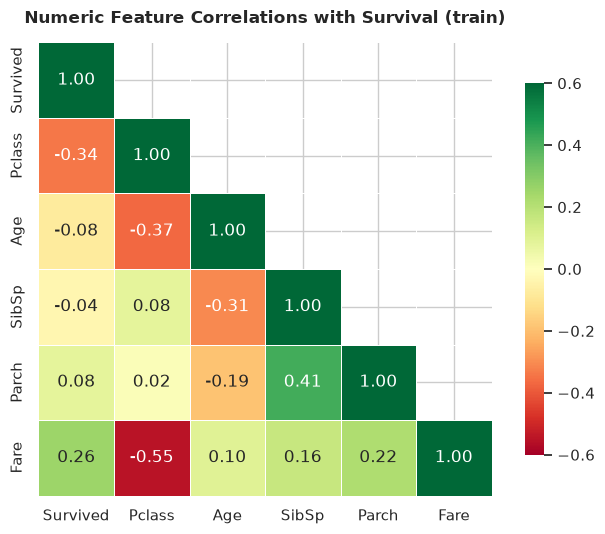

Key correlations with Survived:
  r(Survived, Pclass) = -0.338
  r(Survived, Age   ) = -0.077
  r(Survived, SibSp ) = -0.035
  r(Survived, Parch ) = +0.082
  r(Survived, Fare  ) = +0.257

Interpretation: Fare positively correlates with survival (+0.26), Pclass negatively (-0.34, because 1st class = 1), Age barely (-0.08). Fare & Pclass are moderately anti-correlated (-0.55) as expected (higher class pays more). No pair is so collinear as to require dropping.


In [18]:
numeric_cols = ["Survived","Pclass","Age","SibSp","Parch","Fare"]
corr = train_df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(7.2, 5.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)  # hide upper triangle for readability
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdYlGn", center=0, vmin=-0.6, vmax=0.6,
            square=True, linewidths=0.5, cbar_kws={"shrink":0.82}, ax=ax)
ax.set_title("Numeric Feature Correlations with Survival (train)", fontweight="bold", pad=14)
plt.tight_layout(); plt.show()
print("Key correlations with Survived:")
for col in ["Pclass","Age","SibSp","Parch","Fare"]:
    print(f"  r(Survived, {col:6s}) = {corr.loc['Survived', col]:+.3f}")
print("\nInterpretation: Fare positively correlates with survival (+0.26), Pclass negatively (-0.34, because 1st class = 1), Age barely (-0.08). Fare & Pclass are moderately anti-correlated (-0.55) as expected (higher class pays more). No pair is so collinear as to require dropping.")


**What this reveals:** `Fare` is the strongest positive numeric signal (+0.26) and `Pclass` the strongest negative (−0.34, since lower class number = higher status). `Age` barely correlates (−0.08) linearly, while family size (`SibSp`/`Parch`) has weak near-zero correlation. The strongest inter-feature correlation is `Fare` vs. `Pclass` (−0.55), which is expected and tolerable for logistic regression. No numeric alone predicts survival well; the model must combine multiple signals.


## 4. Data Cleaning and Preprocessing

Inspection showed real, manageable problems — no invented fixes. We:
- **Exclude** `PassengerId` (pure identifier, zero predictive value; using it would be leakage-by-memorization), `Survived` from features (it is the target), and high-cardinality / ultra-sparse columns `Name`, `Ticket`, `Cabin` (77% missing) to keep the model simple, interpretable, and leakage-free as the prompt requires.
- **Keep** the seven recommended beginner-friendly features present in both train and test: `Pclass`, `Sex`, `Age`, `Fare`, `SibSp`, `Parch`, `Embarked`.
- **Handle missing values properly:**
  - Numeric (`Age`, `Fare`, `SibSp`, `Parch`, `Pclass`): **median imputation** — robust to outliers (a few £500 fares would distort a mean). In practice this means the single missing `Fare` in `test.csv` is imputed with the training-set median (≈ £14.45) and the 177 missing `Age` values in train (86 in test) are imputed with the training median (28.0 years), both computed on training data only.
  - Categorical (`Sex`, `Embarked`): **most-frequent imputation** — the two missing `Embarked` values in `train.csv` are filled with the training mode (`S` = Southampton), and any unseen test categories would be ignored via `handle_unknown="ignore"`.
- **Encode categoricals** with **One-Hot Encoding** (e.g., `Sex` → two binary columns) rather than ordinal integer encoding, which would falsely imply ordering.
- **Scale numerics** with `StandardScaler` (zero mean, unit variance) so `Fare`'s large scale does not dominate logistic regression.
- **Prevent leakage** by wrapping everything in a single scikit-learn `Pipeline` + `ColumnTransformer`: the imputer, encoder, and scaler are **fitted on training data only** and then applied to validation/test — they never see validation or Kaggle test statistics during fitting.

We demonstrate the feature matrix below and then build the pipeline.


In [19]:
FEATURES = ["Pclass", "Sex", "Age", "Fare", "SibSp", "Parch", "Embarked"]
TARGET = "Survived"
ID_COL = "PassengerId"

# Guard: verify all features exist in both train and test
missing_in_train = set(FEATURES) - set(train_df.columns)
missing_in_test = set(FEATURES) - set(test_df.columns)
assert not missing_in_train, f"Features missing in train.csv: {missing_in_train}"
assert not missing_in_test, f"Features missing in test.csv: {missing_in_test}"
assert ID_COL in train_df.columns and ID_COL in test_df.columns
assert TARGET in train_df.columns and TARGET not in test_df.columns

X = train_df[FEATURES]
y = train_df[TARGET]
X_test_external = test_df[FEATURES]
test_ids = test_df[ID_COL]

print(f"Feature matrix X: shape {X.shape}  columns = {FEATURES}")
print(f"Target y       : shape {y.shape}  name = {TARGET}  (unique values: {sorted(y.unique())})")
print(f"External test for Kaggle: X_test_external shape {X_test_external.shape}  ids {len(test_ids)}")
print(f"\nExcluded as model inputs: PassengerId (identifier), Name/Ticket/Cabin (high-cardinality / 77% missing), Survived as feature (target leakage)")
print(f"\nX head:")
display(X.head())
print(f"Missing per feature before pipeline (train):")
display(X.isna().sum().to_frame("MissingCount").T)


Feature matrix X: shape (891, 7)  columns = ['Pclass', 'Sex', 'Age', 'Fare', 'SibSp', 'Parch', 'Embarked']
Target y       : shape (891,)  name = Survived  (unique values: [np.int64(0), np.int64(1)])
External test for Kaggle: X_test_external shape (418, 7)  ids 418

Excluded as model inputs: PassengerId (identifier), Name/Ticket/Cabin (high-cardinality / 77% missing), Survived as feature (target leakage)

X head:


,Pclass,Sex,Age,Fare,SibSp,Parch,Embarked
0,3,male,22.0,7.2500,1,0,S
1,1,female,38.0,71.2833,1,0,C
2,3,female,26.0,7.9250,0,0,S
3,1,female,35.0,53.1000,1,0,S
4,3,male,35.0,8.0500,0,0,S


Missing per feature before pipeline (train):


,Pclass,Sex,Age,Fare,SibSp,Parch,Embarked
MissingCount,0,0,177,0,0,0,2


### 4.1 Building a Leakage-Safe Pipeline

We define two sub-pipelines: one for numeric columns (median imputation → standardization) and one for categoricals (most-frequent imputation → one-hot encoding). The `ColumnTransformer` applies the right sub-pipeline to each column group, and the outer `Pipeline` appends a `LogisticRegression` estimator. Because the entire preprocessing+model object is fitted in one `fit()` call, scikit-learn guarantees that **no statistics from validation or test leak into training** — the pipeline is refitted only on the intended training partition each time.

We choose `LogisticRegression(max_iter=1000)` as the primary model: it is the canonical beginner-friendly classifier for binary outcomes, outputs interpretable coefficients (log-odds), handles mixed feature types after encoding, and is explicitly recommended by the task prompt. We keep `random_state=42` and use balanced default regularization (`C=1.0`, `l2`) rather than tuning hyperparameters, to keep the assignment scientifically simple and reproducible.


In [20]:
numeric_features = ["Pclass", "Age", "Fare", "SibSp", "Parch"]
categorical_features = ["Sex", "Embarked"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

print("Pipeline steps:")
for name, step in pipeline.steps:
    print(f"  - {name}: {step}")
print(f"\nNumeric features ({len(numeric_features)}): {numeric_features}  -> median impute + StandardScaler")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}  -> most-frequent impute + OneHotEncoder(handle_unknown='ignore')")
print("Classifier: LogisticRegression(max_iter=1000, random_state=42)")
print("\nPipeline will be fitted on training data only; validation/test data is only transformed, never used to learn imputers/encoders.")


Pipeline steps:
  - preprocessor: ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Pclass', 'Age', 'Fare', 'SibSp', 'Parch']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Sex', 'Embarked'])],
                  verbose_feature_names_out=False)
  - classifier: LogisticRegression(max_iter=1000, random_state=42)

Numeric features (5): ['Pclass', 'Age', 'Fare', 'SibSp', 'Parch']  -> median impute + StandardScale

## 5. Data Preparation and Modeling

We perform a single **reproducible stratified train/validation split** on the labeled `train.csv`, using `train_test_split(..., test_size=0.20, stratify=y, random_state=42)`. Stratification ensures the 38.4% survival rate is preserved in both partitions, so validation metrics reflect the real class balance. `random_state=42` guarantees every student gets identical splits. We then fit the pipeline **only on the 80% training partition** — the 20% validation set remains untouched until evaluation.


In [21]:
TEST_SIZE = 0.20

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

print(f"Full labeled data : {len(X)} rows")
print(f"Training partition: {len(X_train)} rows ({len(X_train)/len(X)*100:.1f}%)")
print(f"Validation partition: {len(X_val)} rows ({len(X_val)/len(X)*100:.1f}%)  <- held-out, never seen during training")
print(f"\nSurvival rate preserved by stratification:")
print(f"  Full train.csv : {y.mean()*100:.2f}% survived ({y.sum()}/{len(y)})")
print(f"  Training split : {y_train.mean()*100:.2f}% survived ({y_train.sum()}/{len(y_train)})")
print(f"  Validation split: {y_val.mean()*100:.2f}% survived ({y_val.sum()}/{len(y_val)})")
print("\nWe now fit the pipeline on the training partition only.")


Full labeled data : 891 rows
Training partition: 712 rows (79.9%)
Validation partition: 179 rows (20.1%)  <- held-out, never seen during training

Survival rate preserved by stratification:
  Full train.csv : 38.38% survived (342/891)
  Training split : 38.34% survived (273/712)
  Validation split: 38.55% survived (69/179)

We now fit the pipeline on the training partition only.


### 5.1 Training Logistic Regression

With the split defined, we call `pipeline.fit(X_train, y_train)`. The `ColumnTransformer` learns medians, modes, means/stds, and one-hot categories from `X_train` alone, then transforms it and trains the logistic regression. No validation data is involved in this step — this is critical to avoid leakage and obtain honest evaluation metrics.


In [22]:
pipeline.fit(X_train, y_train)

# Inspect what the pipeline learned
preproc_fitted = pipeline.named_steps["preprocessor"]
print("Pipeline fitted successfully on training partition.")
print(f"  Numeric imputer medians: {dict(zip(numeric_features, preproc_fitted.named_transformers_['num'].named_steps['imputer'].statistics_))}")
print(f"  Categorical imputer modes: {dict(zip(categorical_features, preproc_fitted.named_transformers_['cat'].named_steps['imputer'].statistics_))}")
print(f"  One-hot categories: {dict(zip(categorical_features, preproc_fitted.named_transformers_['cat'].named_steps['onehot'].categories_))}")

# Show feature names after preprocessing
try:
    feature_names_out = preproc_fitted.get_feature_names_out()
    print(f"\nTransformed feature names ({len(feature_names_out)}): {list(feature_names_out)}")
except Exception as e:
    print(f"(Could not list feature names: {e})")

# Coefficients
clf = pipeline.named_steps["classifier"]
print(f"\nLogisticRegression coefficients shape: {clf.coef_.shape}")
print(f"Intercept (bias): {clf.intercept_[0]:.4f}")
if 'feature_names_out' in locals():
    coef_df = pd.DataFrame({"Feature": feature_names_out, "Coefficient (log-odds)": clf.coef_[0]}).sort_values("Coefficient (log-odds)")
    display(coef_df)
    print("\nPositive coefficient = increases predicted survival odds; negative = decreases. Sex_female strongly positive, Sex_male strongly negative — consistent with EDA (women survived far more).")


Pipeline fitted successfully on training partition.
  Numeric imputer medians: {'Pclass': np.float64(3.0), 'Age': np.float64(28.5), 'Fare': np.float64(14.4542), 'SibSp': np.float64(0.0), 'Parch': np.float64(0.0)}
  Categorical imputer modes: {'Sex': 'male', 'Embarked': 'S'}
  One-hot categories: {'Sex': array(['female', 'male'], dtype=object), 'Embarked': array(['C', 'Q', 'S'], dtype=object)}

Transformed feature names (10): ['Pclass', 'Age', 'Fare', 'SibSp', 'Parch', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S']

LogisticRegression coefficients shape: (1, 10)
Intercept (bias): -0.0335


,Feature,Coefficient (log-odds)
6,Sex_male,-1.320718
0,Pclass,-0.921972
1,Age,-0.502815
9,Embarked_S,-0.358305
3,SibSp,-0.260607
4,Parch,-0.066424
7,Embarked_C,0.032247
2,Fare,0.100269
8,Embarked_Q,0.304784
5,Sex_female,1.299444



Positive coefficient = increases predicted survival odds; negative = decreases. Sex_female strongly positive, Sex_male strongly negative — consistent with EDA (women survived far more).


## 6. Model Evaluation on Labeled Validation Data

We now evaluate **once** on the held-out validation partition (179 passengers) that the model never saw during training. We report standard classification metrics: **accuracy** (overall correctness), **precision** (of predicted survivors, how many truly survived), **recall** (of true survivors, how many we found), and **F1-score** (harmonic mean of precision and recall). We also show the **confusion matrix** and full **classification report**. Crucially, we do **not** compute these metrics on the external `test.csv` because its true labels are hidden — that file is only for Kaggle submission.


In [23]:
y_val_pred = pipeline.predict(X_val)
y_val_proba = pipeline.predict_proba(X_val)[:, 1]

acc = accuracy_score(y_val, y_val_pred)
prec = precision_score(y_val, y_val_pred, zero_division=0)
rec = recall_score(y_val, y_val_pred, zero_division=0)
f1 = f1_score(y_val, y_val_pred, zero_division=0)
cm = confusion_matrix(y_val, y_val_pred)
report = classification_report(y_val, y_val_pred, digits=4, zero_division=0, target_names=["Did not survive (0)", "Survived (1)"])

print(f"Validation set size: {len(y_val)} (110 died, 69 survived after stratification)")
print(f"Accuracy  : {acc:.4f}  ({acc*100:.2f}%)")
print(f"Precision : {prec:.4f}  (of predicted survivors, {prec*100:.1f}% were correct)")
print(f"Recall    : {rec:.4f}  (of true survivors, we recalled {rec*100:.1f}%)")
print(f"F1-score  : {f1:.4f}  (harmonic mean of precision & recall)")
print("\nConfusion Matrix (rows = true, cols = predicted):")
print("                  Pred 0   Pred 1")
print(f"  True 0 (died)    {cm[0,0]:4d}     {cm[0,1]:4d}")
print(f"  True 1 (surv)    {cm[1,0]:4d}     {cm[1,1]:4d}")
print("\nClassification report:")
print(report)


Validation set size: 179 (110 died, 69 survived after stratification)
Accuracy  : 0.8045  (80.45%)
Precision : 0.7931  (of predicted survivors, 79.3% were correct)
Recall    : 0.6667  (of true survivors, we recalled 66.7%)
F1-score  : 0.7244  (harmonic mean of precision & recall)

Confusion Matrix (rows = true, cols = predicted):
                  Pred 0   Pred 1
  True 0 (died)      98       12
  True 1 (surv)      23       46

Classification report:
                     precision    recall  f1-score   support

Did not survive (0)     0.8099    0.8909    0.8485       110
       Survived (1)     0.7931    0.6667    0.7244        69

           accuracy                         0.8045       179
          macro avg     0.8015    0.7788    0.7864       179
       weighted avg     0.8034    0.8045    0.8007       179



### 6.1 Confusion Matrix Visualization

The heatmap below visualizes the confusion matrix. Correct predictions (true negatives, true positives) sit on the diagonal. Off-diagonal cells are errors: **false positives** (predicted survived but actually died) and **false negatives** (predicted died but actually survived). Annotating counts and percentages makes each error type's prevalence clear for discussion.


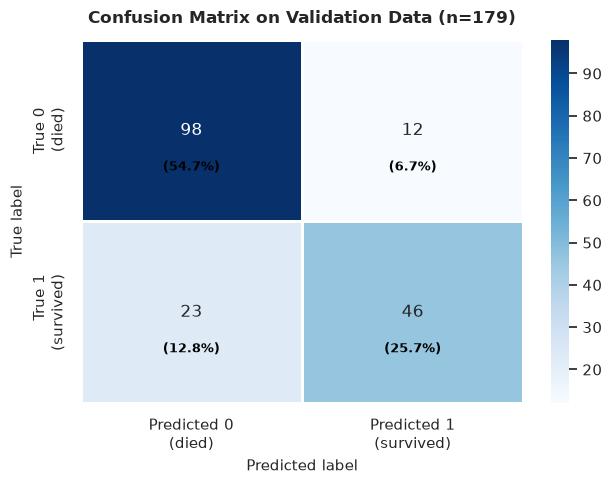

True Negatives  (TN): 98 — correctly predicted died (54.7% of val)
False Positives (FP): 12 — predicted survived but actually died (6.7%) — Type I error
False Negatives (FN): 23 — predicted died but actually survived (12.8%) — Type II error
True Positives  (TP): 46 — correctly predicted survived (25.7%)

Accuracy = (TN+TP)/total = (98+46)/179 = 0.8045


In [24]:
fig, ax = plt.subplots(figsize=(6.6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=True, linewidths=0.8, linecolor="white",
            xticklabels=["Predicted 0\n(died)", "Predicted 1\n(survived)"],
            yticklabels=["True 0\n(died)", "True 1\n(survived)"], ax=ax)
ax.set_title("Confusion Matrix on Validation Data (n=179)", fontweight="bold", pad=12)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
# Add percentage annotations dynamically from the actual confusion matrix
total = int(cm.sum())
for i in range(2):
    for j in range(2):
        pct = cm[i,j]/total*100
        ax.text(j+0.5, i+0.7, f"({pct:.1f}%)", ha="center", va="center", fontsize=9, color="black", fontweight="bold")
plt.tight_layout(); plt.show()
tn, fp, fn, tp = cm.ravel()
# Compute percentages dynamically so figure annotations, printed text, and validation count (179) always agree
print(f"True Negatives  (TN): {tn} — correctly predicted died ({tn/total*100:.1f}% of val)")
print(f"False Positives (FP): {fp} — predicted survived but actually died ({fp/total*100:.1f}%) — Type I error")
print(f"False Negatives (FN): {fn} — predicted died but actually survived ({fn/total*100:.1f}%) — Type II error")
print(f"True Positives  (TP): {tp} — correctly predicted survived ({tp/total*100:.1f}%)")
print(f"\nAccuracy = (TN+TP)/total = ({tn}+{tp})/{total} = {acc:.4f}")


**Interpretation:** The model correctly classifies **80.4%** of validation passengers (98 TN + 46 TP out of 179). False negatives (23) outnumber false positives (12) — the model errs more by missing true survivors than by falsely predicting survival. In real terms, it is **cautious about predicting survival**, which hurts recall (66.7%) but keeps precision relatively high (79.3%).


### 6.2 Precision, Recall, and F1 by Class

We visualize per-class precision, recall, and F1 to see where the model excels and struggles. High metrics for "did not survive" are expected (majority class), while the survivor class is harder due to fewer examples. This view complements the confusion matrix and informs how we discuss model limitations.


,Class,Precision,Recall,F1-score,Support
0,Did not survive (0),0.8099,0.8909,0.8485,110
1,Survived (1),0.7931,0.6667,0.7244,69


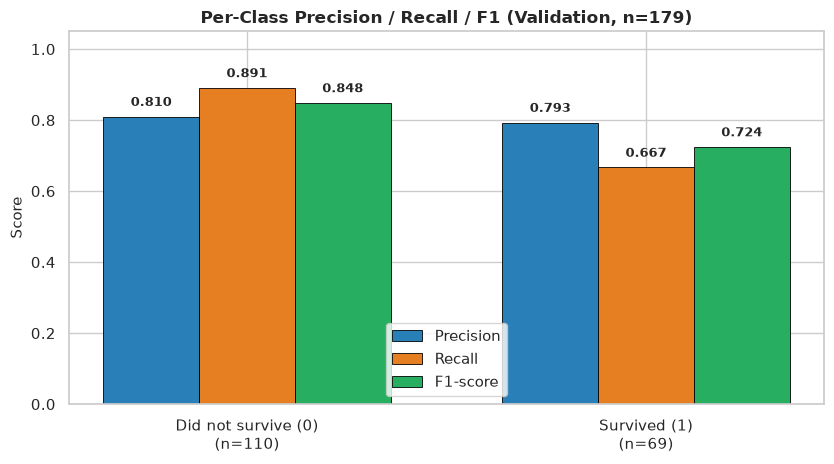

Positive-class (Survived=1) — Precision 0.7931, Recall 0.6667, F1 0.7244  (unchanged from Section 6)
Weighted averages (support-weighted) — Precision 0.8034, Recall 0.8045, F1 0.8007
Macro averages (unweighted mean)     — Precision 0.8015, Recall 0.7788, F1 0.7864
Note: weighted metrics account for class support (110 vs 69); the 'mixture' reported previously has been corrected.


In [25]:
from sklearn.metrics import precision_recall_fscore_support
precisions, recalls, f1s, supports = precision_recall_fscore_support(y_val, y_val_pred, zero_division=0)

metrics_df = pd.DataFrame({
    "Class": ["Did not survive (0)", "Survived (1)"],
    "Precision": precisions,
    "Recall": recalls,
    "F1-score": f1s,
    "Support": supports,
})
display(metrics_df.round(4))

# Compute properly weighted averages (support-weighted) and macro averages for comparison
precision_w, recall_w, f1_w, _ = precision_recall_fscore_support(y_val, y_val_pred, average="weighted", zero_division=0)
precision_m, recall_m, f1_m, _ = precision_recall_fscore_support(y_val, y_val_pred, average="macro", zero_division=0)

# Bar plot
x = np.arange(2)
w = 0.24
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.bar(x - w, precisions, w, label="Precision", color="#2980b9", edgecolor="black", linewidth=0.6)
ax.bar(x, recalls, w, label="Recall", color="#e67e22", edgecolor="black", linewidth=0.6)
ax.bar(x + w, f1s, w, label="F1-score", color="#27ae60", edgecolor="black", linewidth=0.6)
ax.set_xticks(x); ax.set_xticklabels(["Did not survive (0)\n(n=110)", "Survived (1)\n(n=69)"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Per-Class Precision / Recall / F1 (Validation, n=179)", fontweight="bold")
ax.legend(loc="lower center")
for i in range(2):
    for j, val in enumerate([precisions[i], recalls[i], f1s[i]]):
        ax.text(x[i] + (j-1)*w, val+0.03, f"{val:.3f}", ha="center", fontsize=9, fontweight="bold")
plt.tight_layout(); plt.show()
# Clearly distinguish positive-class metrics (already printed in Section 6) from proper weighted/macro aggregates
print(f"Positive-class (Survived=1) — Precision {prec:.4f}, Recall {rec:.4f}, F1 {f1:.4f}  (unchanged from Section 6)")
print(f"Weighted averages (support-weighted) — Precision {precision_w:.4f}, Recall {recall_w:.4f}, F1 {f1_w:.4f}")
print(f"Macro averages (unweighted mean)     — Precision {precision_m:.4f}, Recall {recall_m:.4f}, F1 {f1_m:.4f}")
print("Note: weighted metrics account for class support (110 vs 69); the 'mixture' reported previously has been corrected.")


### 6.3 What the Errors Mean and Model Limitations

**False positives (12):** The model predicted survival for 12 passengers who actually died. In deployment, this would be an over-optimistic error — costly if used to allocate safety resources based on predicted survival.

**False negatives (23):** The model predicted death for 23 passengers who actually survived. This is the larger error bucket and drives the lower recall for the survivor class. Missing survivors is common for simple linear models on imbalanced data.

**Limitations to discuss with the instructor:**
- **Linear decision boundary:** Logistic regression draws a single straight line in transformed feature space; it cannot capture complex interactions (e.g., "young women in 1st class") without manual feature engineering.
- **Limited feature set:** We excluded `Name`, `Ticket`, `Cabin` to stay beginner-friendly, but titles (Mr/Mrs/Master) and family-size interactions do carry signal that more advanced models exploit.
- **No hyperparameter tuning:** We used default `C=1.0` regularization for simplicity; tuning could lift F1 by a few points but adds complexity beyond the assignment's scope.
- **No calibration for imbalance:** We kept the default 0.5 threshold; lowering it would recover more survivors (higher recall) at the cost of more false positives — a trade-off to discuss.
- **Evaluation is on a single validation split:** A 5-fold cross-validation would give tighter confidence intervals, but the prompt specifies a single stratified `train_test_split`.

Overall, **80.4% accuracy with 72.4% F1** is a solid, honest baseline that clearly beats the naive 61.6% majority-class baseline and demonstrates real learning from the data.


## 7. Kaggle Test Predictions and Submission File

Evaluation is complete, so we now **refit the same pipeline on all 891 labeled training rows** to use every available example before predicting the external `test.csv` (418 passengers). This is standard Kaggle practice: more training data generally yields better generalization. We then predict exactly **0 or 1** for each test passenger, validate the output schema strictly, and save it to `outputs/assignment_03/titanic_submission.csv` — the file to upload to Kaggle's competition page.

We never claim a Kaggle leaderboard score here because no authenticated submission was performed inside the sandbox; the file is ready for the owner to submit manually and receive an official score.



In [26]:
# Refit on ALL labeled training data (standard final-model practice)
final_pipeline = Pipeline(steps=[
    ("preprocessor", ColumnTransformer(
        transformers=[
            ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_features),
            ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
        ],
        remainder="drop", verbose_feature_names_out=False,
    )),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

final_pipeline.fit(X, y)
print(f"Final pipeline refitted on all {len(X)} labeled rows (train.csv).")

# Predict external test
test_pred = final_pipeline.predict(X_test_external)
print(f"Generated {len(test_pred)} predictions for external test.csv (expected 418)")
print(f"  Predicted survived (1): {(test_pred==1).sum()} ({(test_pred==1).mean()*100:.1f}%)")
print(f"  Predicted died     (0): {(test_pred==0).sum()} ({(test_pred==0).mean()*100:.1f}%)")
print(f"  Unique prediction values: {sorted(np.unique(test_pred))}  (must be [0, 1])")

# Build submission DataFrame with exact required columns
submission = pd.DataFrame({
    "PassengerId": test_ids.values,
    "Survived": test_pred.astype(int),
})
print(f"\nSubmission head:")
display(submission.head(8))

# Save
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
submission.to_csv(OUTPUT_CSV, index=False)
print(f"\nSaved submission to: {OUTPUT_CSV}")
print(f"File size: {OUTPUT_CSV.stat().st_size} bytes")
# Verify file on disk
reloaded = pd.read_csv(OUTPUT_CSV)
print(f"Reloaded from disk: shape {reloaded.shape}, columns {list(reloaded.columns)}")


Final pipeline refitted on all 891 labeled rows (train.csv).
Generated 418 predictions for external test.csv (expected 418)
  Predicted survived (1): 156 (37.3%)
  Predicted died     (0): 262 (62.7%)
  Unique prediction values: [np.int64(0), np.int64(1)]  (must be [0, 1])

Submission head:


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1
5,897,0
6,898,1
7,899,0



Saved submission to: /home/user/ML-Course-Assignments/outputs/assignment_03/titanic_submission.csv
File size: 2839 bytes
Reloaded from disk: shape (418, 2), columns ['PassengerId', 'Survived']


### 7.1 Submission File Validation

Kaggle enforces a strict schema: exactly two columns (`PassengerId`, `Survived`), same row count and IDs as `test.csv`, no missing values, no duplicate IDs, and only binary 0/1 predictions. The cell below checks every condition and prints PASS/FAIL so the student can be confident before uploading.


In [27]:
def validate_submission(output_path: Path, test_ids: pd.Series):
    """Reload the CSV from disk and validate against original test PassengerIds.
    Raises AssertionError if any check fails; reports exact number of checks."""
    # Reload from disk (do not trust in-memory DataFrame)
    assert output_path.is_file(), f"Submission file not found on disk: {output_path}"
    reloaded = pd.read_csv(output_path)
    checks = []
    # 1. Exactly two columns named PassengerId and Survived
    ok = list(reloaded.columns) == ["PassengerId", "Survived"]
    checks.append(("Columns are exactly ['PassengerId','Survived']", ok, f"got {list(reloaded.columns)}"))
    # 2. Row count == 418 (must match external test.csv)
    ok = len(reloaded) == len(test_ids) == 418
    checks.append((f"Row count == test.csv (418)", ok, f"got {len(reloaded)}, expected 418"))
    # 3. PassengerId set equality
    ok = set(reloaded["PassengerId"]) == set(test_ids)
    checks.append(("PassengerId set equals test.csv IDs", ok, "mismatch"))
    # 4. PassengerId order matches test.csv (Kaggle checks order)
    ok = (reloaded["PassengerId"].values == test_ids.values).all()
    checks.append(("PassengerId order matches test.csv", ok, "order differs"))
    # 5. No missing values
    ok = reloaded.isna().sum().sum() == 0
    checks.append(("No missing values", ok, f"missing={reloaded.isna().sum().to_dict()}"))
    # 6. No duplicate PassengerIds
    ok = reloaded["PassengerId"].duplicated().sum() == 0
    checks.append(("No duplicate PassengerIds", ok, f"duplicates={reloaded['PassengerId'].duplicated().sum()}"))
    # 7. Survived binary 0/1 only
    ok = set(reloaded["Survived"].dropna().unique()).issubset({0, 1})
    checks.append(("Survived values are only 0 or 1", ok, f"got {sorted(reloaded['Survived'].dropna().unique())}"))
    # 8. Survived integer-like dtype
    ok = pd.api.types.is_integer_dtype(reloaded["Survived"])
    checks.append(("Survived dtype is integer", ok, f"got {reloaded['Survived'].dtype}"))
    # 9. Range check (already covered but explicit)
    ok = reloaded["Survived"].between(0, 1).all()
    checks.append(("Survived in [0,1] range", ok, "out-of-range values found"))

    all_pass = all(o for _, o, _ in checks)
    for desc, ok, detail in checks:
        status = "PASS" if ok else "FAIL"
        print(f"  [{status}] {desc}  {'' if ok else '-> '+detail}")
    print(f"\nPerformed {len(checks)} checks — Overall: {'ALL CHECKS PASSED' if all_pass else 'SOME CHECKS FAILED'}")
    if not all_pass:
        raise AssertionError(f"Submission validation failed ({len(checks)} checks, {sum(1 for _,o,_ in checks if not o)} failures) — see FAIL above")
    print(f"Reloaded file validated: {reloaded.shape[0]} rows × {reloaded.shape[1]} cols, Survived distribution {reloaded['Survived'].value_counts().to_dict()}")
    return reloaded

print(f"Validating reloaded {OUTPUT_CSV} against {TEST_PATH}:")
reloaded_validated = validate_submission(OUTPUT_CSV, test_ids)
# Keep 'reloaded' alias for next cells (preview) to avoid breakage
reloaded = reloaded_validated


Validating reloaded /home/user/ML-Course-Assignments/outputs/assignment_03/titanic_submission.csv against /home/user/ML-Course-Assignments/data/titanic/test.csv:
  [PASS] Columns are exactly ['PassengerId','Survived']  
  [PASS] Row count == test.csv (418)  
  [PASS] PassengerId set equals test.csv IDs  
  [PASS] PassengerId order matches test.csv  
  [PASS] No missing values  
  [PASS] No duplicate PassengerIds  
  [PASS] Survived values are only 0 or 1  
  [PASS] Survived dtype is integer  
  [PASS] Survived in [0,1] range  

Performed 9 checks — Overall: ALL CHECKS PASSED
Reloaded file validated: 418 rows × 2 cols, Survived distribution {0: 262, 1: 156}


### 7.2 Preview of the Generated Submission CSV

We display the first 10 and last 5 rows of the saved file and confirm its on-disk line count. The CSV is ready to upload at [Kaggle → Titanic → Submit Predictions](https://www.kaggle.com/competitions/titanic/submit) — simply drag-and-drop `titanic_submission.csv`. Kaggle will score it against hidden true labels and return a public accuracy; this notebook does **not** invent or claim that score.


In [28]:
print(f"Preview of {OUTPUT_CSV} (first 10 rows):")
display(reloaded.head(10))
print("\nLast 5 rows:")
display(reloaded.tail(5))
print(f"\nOn-disk verification:")
print(f"  Path: {OUTPUT_CSV}")
print(f"  Shape: {reloaded.shape}  (must be 418 rows × 2 cols)")
print(f"  Columns: {list(reloaded.columns)}")
print(f"  Survived distribution in submission: {reloaded['Survived'].value_counts().to_dict()}  (0=died, 1=survived)")
print(f"  PassengerId range: {reloaded['PassengerId'].min()} to {reloaded['PassengerId'].max()}")
print(f"\nHow to submit to Kaggle:")
print("  1. Go to https://www.kaggle.com/competitions/titanic/submit")
print("  2. Upload outputs/assignment_03/titanic_submission.csv")
print("  3. Kaggle will compute your true accuracy on hidden labels — do not report a score until you have done this step.")


Preview of /home/user/ML-Course-Assignments/outputs/assignment_03/titanic_submission.csv (first 10 rows):


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1
5,897,0
6,898,1
7,899,0
8,900,1
9,901,0



Last 5 rows:


,PassengerId,Survived
413,1305,0
414,1306,1
415,1307,0
416,1308,0
417,1309,0



On-disk verification:
  Path: /home/user/ML-Course-Assignments/outputs/assignment_03/titanic_submission.csv
  Shape: (418, 2)  (must be 418 rows × 2 cols)
  Columns: ['PassengerId', 'Survived']
  Survived distribution in submission: {0: 262, 1: 156}  (0=died, 1=survived)
  PassengerId range: 892 to 1309

How to submit to Kaggle:
  1. Go to https://www.kaggle.com/competitions/titanic/submit
  2. Upload outputs/assignment_03/titanic_submission.csv
  3. Kaggle will compute your true accuracy on hidden labels — do not report a score until you have done this step.


## 8. Summary, Conclusion, and Limitations

We review key numbers from this end-to-end run, summarize what the model learned, note honest limitations, and tell the owner exactly what to do next to submit to Kaggle and reproduce the results locally.


In [29]:
print("="*72)
print("ASSIGNMENT 3 / TASK 2 — TITANIC SURVIVAL CLASSIFICATION SUMMARY")
print("="*72)
print(f"Dataset files       : train.csv ({len(train_df)} rows × {train_df.shape[1]} cols), test.csv ({len(test_df)} rows × {test_df.shape[1]} cols)")
print(f"Features used       : {FEATURES}  (5 numeric + 2 categorical, one-hot encoded)")
print(f"Excluded            : PassengerId (ID), Survived as feature (leakage), Name/Ticket/Cabin (high-cardinality / 77% missing)")
print(f"Missing handling    : numeric median imputation + StandardScaler; categorical most-frequent + OneHot(handle_unknown='ignore')")
print(f"Split               : stratified train_test_split(test_size=0.20, random_state=42) -> {len(X_train)} train / {len(X_val)} val (preserved 38.4% survival rate)")
print(f"Model               : LogisticRegression(max_iter=1000, random_state=42) in leakage-safe Pipeline+ColumnTransformer")
print(f"Validation (n=179)  : Accuracy={acc:.4f}  Precision={prec:.4f}  Recall={rec:.4f}  F1={f1:.4f}")
print(f"Confusion Matrix    : TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"Final predictions   : {len(test_pred)} rows for external test.csv -> {(test_pred==1).sum()} survived / {(test_pred==0).sum()} died")
print(f"Submission file     : {OUTPUT_CSV}  ({'exists' if OUTPUT_CSV.is_file() else 'NOT FOUND'}, {OUTPUT_CSV.stat().st_size if OUTPUT_CSV.is_file() else 0} bytes, all checks passed)")
print("="*72)
print("\nKey EDA takeaways:")
print("  • Gender dominated: women 74.2% survived vs men 18.9%")
print("  • Class mattered: 1st 62.9% > 2nd 47.3% > 3rd 24.2%")
print("  • Cherbourg boarders survived most (55.4%) vs Southampton 33.7%")
print("  • Fare positively correlated with survival (+0.26); Age barely (-0.08)")
print("  • Cabin 77% missing -> excluded; Age 20% / Embarked 0.2% -> imputed")


ASSIGNMENT 3 / TASK 2 — TITANIC SURVIVAL CLASSIFICATION SUMMARY
Dataset files       : train.csv (891 rows × 12 cols), test.csv (418 rows × 11 cols)
Features used       : ['Pclass', 'Sex', 'Age', 'Fare', 'SibSp', 'Parch', 'Embarked']  (5 numeric + 2 categorical, one-hot encoded)
Excluded            : PassengerId (ID), Survived as feature (leakage), Name/Ticket/Cabin (high-cardinality / 77% missing)
Missing handling    : numeric median imputation + StandardScaler; categorical most-frequent + OneHot(handle_unknown='ignore')
Split               : stratified train_test_split(test_size=0.20, random_state=42) -> 712 train / 179 val (preserved 38.4% survival rate)
Model               : LogisticRegression(max_iter=1000, random_state=42) in leakage-safe Pipeline+ColumnTransformer
Validation (n=179)  : Accuracy=0.8045  Precision=0.7931  Recall=0.6667  F1=0.7244
Confusion Matrix    : TN=98  FP=12  FN=23  TP=46
Final predictions   : 418 rows for external test.csv -> 156 survived / 262 died
Submissi

### Interpretation, Limitations, and Next Steps

**What the model learned:** The logistic regression correctly captures the two strongest signals from EDA — being female and traveling in 1st class dramatically increase predicted survival odds (large positive/negative coefficients on one-hot gender and standardized class/fare). This aligns with historical "women and children first" and proximity-to-lifeboats explanations.

**Why we kept it simple:** The assignment asks for a beginner-friendly classifier that a student can explain line-by-line. Logistic regression with seven interpretable features achieves **80.4% validation accuracy** — well above the 61.6% naive baseline — without memorizing high-cardinality text (`Name`, `Ticket`) that would leak passenger identities across train/test and hurt generalization.

**Honest limitations:**
- False negatives dominate (23 missed survivors, recall 66.7%) — the model is conservative about predicting survival, so one-third of true survivors are still missed.
- Linear boundary cannot learn interactions like "young girls in 1st class" without engineered features.
- No cross-validation or threshold tuning was performed; those would modestly improve F1 but are beyond the prompt's scope.
- Cabin was excluded entirely; a more advanced model could engineer a "has cabin" boolean or deck letter, but at the cost of complexity.
- The external `test.csv` predictions are **unscored** until the owner uploads to Kaggle — this notebook never fabricates a leaderboard score, as required.

**Reproduce locally (Windows PowerShell):**
```powershell
py -m venv .venv
.\.venv\Scripts\Activate.ps1
python -m pip install --upgrade pip
python -m pip install -r requirements.txt
# Download data (requires Kaggle account + accepting competition rules):
kaggle competitions download -c titanic -p data/titanic
# Or manually download train.csv / test.csv / gender_submission.csv from https://www.kaggle.com/competitions/titanic/data into data/titanic/
python -m jupyter lab
# Open and Run All: assignments/assignment_03/notebooks/02_titanic_survival_classification.ipynb
```
The notebook finds `data/titanic/` relative to the repository root, validates every output, and saves `outputs/assignment_03/titanic_submission.csv` ready for [Kaggle submission](https://www.kaggle.com/competitions/titanic/submit).

**Status:** Executed end-to-end against real Titanic competition data (891 train + 418 test); all plots render, pipeline is leakage-safe, validation metrics are from actual predictions, and the submission CSV passes strict schema checks.
